✅ 本次放电循环总容量为: 1.5447 Ah


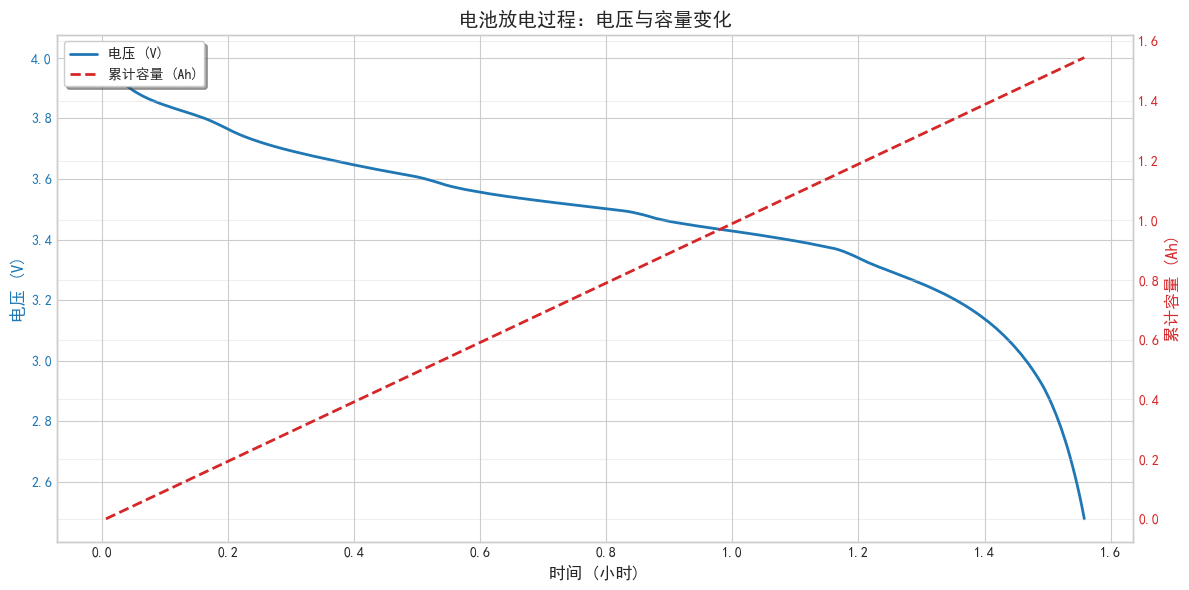

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# ==================== 1. 环境设置 ====================
# 设置清爽的图表风格
plt.style.use('seaborn-v0_8-whitegrid')

# 设置中文字体，防止图表中的中文显示为方块
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 用 SimHei，Mac 请改为 ['Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False    # 正常显示负号

# ==================== 2. 读取数据 ====================
# 请确保文件路径正确
file_path = "./data/00005.csv"
df = pd.read_csv(file_path)

# ==================== 3. 数据预处理与特征工程 ====================
# 将时间从秒转换为小时，方便后续积分计算和图表阅读
df['Time_h'] = df["Time"] / 3600

# 筛选出真正的放电阶段
# 剔除电流接近0的静置阶段和放电末尾的电压反弹（弛豫）干扰
df_discharge = df[df['Current_measured'] < -0.1].copy()

# 计算时间差（相邻两个采样点的时间间隔，单位为小时）
df_discharge['dt_h'] = df_discharge['Time_h'].diff().fillna(0)

# 安时积分：计算每个时间步长内流出的电量 (安培 * 小时 = Ah)
df_discharge['Ah_step'] = abs(df_discharge['Current_measured']) * df_discharge['dt_h']

# 累计求和，得到每个时间点的总放电容量
df_discharge['Capacity_Ah'] = df_discharge['Ah_step'].cumsum()

# 提取最终的总放电容量（本次循环的容量），用于终端打印
final_capacity = df_discharge['Capacity_Ah'].iloc[-1]
print(f"✅ 本次放电循环总容量为: {final_capacity:.4f} Ah")

# ==================== 4. 绘制双Y轴曲线 ====================
fig, ax1 = plt.subplots(figsize=(12, 6))

# --- 左轴：绘制电压曲线（蓝色） ---
color_voltage = '#1f77b4'
ax1.plot(df_discharge['Time_h'], df_discharge['Voltage_measured'], 
         color=color_voltage, linewidth=2, label='电压 (V)')
ax1.set_xlabel('时间 (小时)', fontsize=12)
ax1.set_ylabel('电压 (V)', color=color_voltage, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_voltage)

# --- 右轴：绘制累计容量曲线（红色虚线） ---
ax2 = ax1.twinx()  # 创建共享X轴的第二个Y轴
color_capacity = '#d62728'
ax2.plot(df_discharge['Time_h'], df_discharge['Capacity_Ah'], 
         color=color_capacity, linewidth=2, linestyle='--', label='累计容量 (Ah)')
ax2.set_ylabel('累计容量 (Ah)', color=color_capacity, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_capacity)

# --- 合并图例并美化 ---
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10, frameon=True, shadow=True)

plt.title('电池放电过程：电压与容量变化', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()